In [11]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd()
ROOT = cwd.parent if cwd.name == "notebooks" else cwd
RESULTS = ROOT / "results"

files = {
    "synthetic": "model_comparison.csv",
    "trend": "trend_stress_results.csv",
    "noise": "noise_stress_results.csv",
    "seeds": "multi_seed_results.csv",
    "real": "real_world_results.csv",
}

for name, filename in files.items():
    path = RESULTS / filename
    print(f"{name:12s} {'PASS' if path.exists() else 'MISSING'}")

synthetic    PASS
trend        PASS
noise        PASS
seeds        PASS
real         PASS


In [1]:
import sys
from pathlib import Path

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import pandas as pd
import matplotlib.pyplot as plt

from utils import (
    set_seed,
    create_windows,
    Linear,
    DLinear,
    NLinear,
    train_model,
    evaluate_model,
    train_one_epoch,
    validate,
    run_experiment,
    prepare_data
)

In [2]:
datasets = {
    name: pd.read_csv(RESULTS / filename)
    for name, filename in files.items()
}

for name, df in datasets.items():
    print(f"\n{name.upper()}")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("Missing:", df.isna().sum().sum())

    assert (df["MSE"] >= 0).all()
    assert (df["MAE"] >= 0).all()
    assert np.isfinite(df[["MSE", "MAE"]].to_numpy()).all()


SYNTHETIC
Shape: (15, 9)
Columns: ['Model', 'P', 'L', 'T', 'L/P', 'T/P', 'MSE', 'MAE', 'Seed']
Missing: 0

TREND
Shape: (12, 11)
Columns: ['Model', 'P', 'L', 'T', 'L/P', 'T/P', 'Trend', 'Noise', 'MSE', 'MAE', 'Seed']
Missing: 0

NOISE
Shape: (15, 11)
Columns: ['Model', 'P', 'L', 'T', 'L/P', 'T/P', 'Trend', 'Noise', 'MSE', 'MAE', 'Seed']
Missing: 0

SEEDS
Shape: (27, 11)
Columns: ['Model', 'P', 'L', 'T', 'L/P', 'T/P', 'Trend', 'Noise', 'MSE', 'MAE', 'Seed']
Missing: 0

REAL
Shape: (12, 12)
Columns: ['Dataset', 'Model', 'P', 'L', 'T', 'L/P', 'T/P', 'MSE', 'MAE', 'Best_epoch', 'Best_val_MSE', 'Seed']
Missing: 0


In [3]:
for name, df in datasets.items():

    keys = [
        c for c in
        ["Model", "P", "L", "T", "Trend", "Noise", "Seed"]
        if c in df.columns
    ]

    duplicates = df.duplicated(subset=keys).sum()

    print(f"{name}: {duplicates} duplicated configurations")

synthetic: 0 duplicated configurations
trend: 0 duplicated configurations
noise: 0 duplicated configurations
seeds: 0 duplicated configurations
real: 0 duplicated configurations


In [4]:
# Hiệu suất tương đối của Dlinear thay đổi như thế nào theo số chu kỳ được quan sát (T/P) và số chu kỳ trong quá khứ (L/P)?

synthetic = datasets["synthetic"]

geometry = synthetic.pivot_table(
    index=["L/P", "T/P"],
    columns="Model",
    values="MSE"
)

geometry["Gain_%"] = (
    (geometry["Linear"] - geometry["DLinear"])
    / geometry["Linear"]
) * 100

geometry["Winner"] = geometry[
    ["Linear", "DLinear", "NLinear"]
].idxmin(axis=1)

geometry.round(4)

Model    DLinear  Linear  NLinear    Gain_%  Winner
L/P T/P                                            
0.5 8.0      0.0     0.0      0.0   -1.3229  Linear
1.0 1.0      0.0     0.0      0.0   -6.6785  Linear
    4.0      0.0     0.0      0.0   -4.3360  Linear
4.0 1.0      0.0     0.0      0.0 -792.1333  Linear
    4.0      0.0     0.0      0.0 -306.2429  Linear

In [7]:
geometry.style.format({
    "Linear": "{:.6e}",
    "DLinear": "{:.6e}",
    "NLinear": "{:.6e}",
    "Gain_%": "{:.2f}"
})

**Nhận xét:**
* **DLinear thắng ở những vùng nào?**
  * Dựa vào cột Winner trong bảng, không có vùng nào mà DLinear thắng; toàn bộ các trường hợp đều có winner là Linear.

* **Gain thay đổi thế nào khi T/P tăng?**
  * Khi T/P tăng, giá trị Gain_% có xu hướng tăng lên. 
  * Ví dụ:
    * Khi L/P = 1.0, lúc T/P = 1.0 thì Gain_% là -6.6785, nhưng khi T/P = 4.0 thì Gain_% tăng lên thành -4.3360.
    * Khi L/P = 4.0, lúc T/P = 1.0 thì Gain_% là -792.1333, nhưng khi T/P = 4.0 thì Gain_% tăng lên thành -306.2429.

* **Khi L/P tăng, có cải thiện nhất quán không?**
  * Không có sự cải thiện nhất quán. Khi L/P tăng (từ 1.0 lên 4.0), giá trị Gain_% sụt giảm mạnh.
  * Ví dụ: Ở mức T/P = 1.0, khi L/P tăng từ 1.0 lên 4.0, Gain_% lao dốc từ -6.6785 xuống -792.1333.

* **Có vùng chuyển tiếp giữa Gain dương và âm không?**
  * Không. Tất cả các giá trị Gain_% được ghi nhận trong bảng đều là số âm (từ khoảng -1.32 đến -792.13). Do đó, chưa xuất hiện vùng có Gain dương để tạo ra điểm chuyển tiếp giữa dương và âm trong phạm vi dữ liệu này.

Thật ra điều này hợp lý với giả thuyết 1 model basic Linear có thể học rất tốt tín hiệu biểu đồ hình sin sạch, vốn đã có tính tuần hoàn rõ ràng. Tuy nhiên đây mới là loại syntheric signal và 1 tập configuration nhỏ.

In [5]:
# Trend và Noise

def calculate_gain_table(df, variable):
    table = df.pivot_table(
        index=variable,
        columns="Model",
        values="MSE"
    )

    table["Gain_%"] = (
        (table["Linear"] - table["DLinear"])
        / table["Linear"]
    ) * 100

    return table

trend_table = calculate_gain_table(
    datasets["trend"], "Trend"
)

noise_table = calculate_gain_table(
    datasets["noise"], "Noise"
)

display(trend_table)
display(noise_table)

Model,DLinear,Linear,NLinear,Gain_%
Trend,,,,
0.0000,4.429892e-06,1.090454e-06,0.000008,-306.242917
0.0001,2.887472e-07,6.536445e-08,0.000006,-341.749677
0.0005,2.340807e-06,1.757603e-06,0.000011,-33.181820
0.0010,3.647849e-06,3.903867e-05,0.000008,90.655807


Model,DLinear,Linear,NLinear,Gain_%
Noise,,,,
0.0,0.000004,0.000001,0.000008,-306.242917
0.1,0.011109,0.011178,0.011466,0.616328
0.3,0.098275,0.097666,0.099165,-0.624345
0.5,0.270510,0.269457,0.273762,-0.390744
1.0,1.074365,1.072711,1.087997,-0.154180


**Nhận xét:**

* **Trend sensitivity (Lợi ích của DLinear thay đổi thế nào khi linear trend mạnh lên?)**
  * Khi xu hướng tuyến tính Linear trend tăng dần từ 0.0000 lên 0.0010, giá trị Gain_% thay đổi theo chiều hướng cải thiện: từ mức âm (-306.24) tăng dần và chuyển sang dương  90.6558 ở mức trend 0.0010.
  * Điều này cho thấy khi linear trend càng mạnh, lợi ích và hiệu năng của DLinear được cải thiện, vượt trội hơn so với mô hình Linear thông thường.

* **Noise sensitivity (DLinear có giữ được lợi thế tương đối khi noise tăng không?)**
  * Khi mức độ nhiễu Noise tăng từ 0.0 lên các mốc cao hơn (0.1, 0.3, 0.5, 1.0), giá trị Gain_% dao động sát mốc 0 tăng nhẹ lên dương ở mức 0.1 là 0.6163, nhưng sau đó lại lùi về các mức âm như -0.62, -0.39, -0.15.
  * Như vậy, DLinear không giữ được lợi thế tương đối ổn định khi noise tăng; hiệu năng của mô hình không duy trì được xu hướng cải thiện mà dao động quanh ngưỡng tương đương với Linear.

#### Em muốn tìm hiểu thêm mức trend giữa 0.0005 và 0.001 xem có 1 ngưỡng trend nào mà bắt đầu từ đó thì Dlinear vượt trội 1 cách ổn định không?

In [2]:
transition_trends = [
    0.0005,
    0.0006,
    0.0007,
    0.0008,
    0.0009,
    0.0010
]

seeds = [42, 123, 2026]

transition_results = []

for trend_slope in transition_trends:

    for seed in seeds:

        for model_name in ["Linear", "DLinear", "NLinear"]:

            result = run_experiment(
                model_name=model_name,
                period=24,
                lookback=96,
                horizon=96,
                trend_slope=trend_slope,
                noise_std=0.0,
                epochs=50,
                seed=seed
            )

            transition_results.append(result)

transition_df = pd.DataFrame(transition_results)

Epoch   1/50 | Train MSE: 0.199865 | Val MSE: 0.002135
Epoch  10/50 | Train MSE: 0.000021 | Val MSE: 0.000030
Epoch  20/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  30/50 | Train MSE: 0.000000 | Val MSE: 0.000002
Epoch  40/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  50/50 | Train MSE: 0.000010 | Val MSE: 0.000001
Epoch   1/50 | Train MSE: 0.202100 | Val MSE: 0.002341
Epoch  10/50 | Train MSE: 0.000002 | Val MSE: 0.000003
Epoch  20/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  30/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  40/50 | Train MSE: 0.000000 | Val MSE: 0.000002
Epoch  50/50 | Train MSE: 0.000004 | Val MSE: 0.000002
Epoch   1/50 | Train MSE: 0.117293 | Val MSE: 0.000620
Epoch  10/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  20/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  30/50 | Train MSE: 0.000001 | Val MSE: 0.000000
Epoch  40/50 | Train MSE: 0.000000 | Val MSE: 0.000000
Epoch  50/50 | Train MSE: 0.000003 | Val MSE: 0.000011
Epoch   1/

In [4]:
print(transition_df.dtypes)

print("\nFirst MSE value:")
print(transition_df["MSE"].iloc[0])

print("\nType:")
print(type(transition_df["MSE"].iloc[0]))

Model           str
Period        int64
Lookback      int64
Horizon       int64
L/P         float64
T/P         float64
Trend       float64
Noise       float64
Seed          int64
MSE          object
dtype: object

First MSE value:
(1.728763891151175e-06, 0.0003932785475626588, array([[2.6250188, 2.8326373, 2.9919848, ..., 1.912715 , 2.162679 ,
        2.431375 ],
       [2.8326364, 2.992084 , 3.092392 , ..., 2.1720262, 2.4220555,
        2.6730475],
       [2.992032 , 3.092466 , 3.1269712, ..., 2.4313924, 2.664007 ,
        2.880608 ],
       ...,
       [3.4509678, 3.4174528, 3.317956 , ..., 3.2045941, 3.3548853,
        3.464455 ],
       [3.4173965, 3.3180673, 3.1595333, ..., 3.3640363, 3.4558547,
        3.4989705],
       [3.317989 , 3.1596227, 2.952925 , ..., 3.4643822, 3.4910834,
        3.4653716]], shape=(655, 96), dtype=float32), array([[2.6250544, 2.8326807, 2.9920373, ..., 1.9126906, 2.1720514,
        2.4314086],
       [2.8326807, 2.9920373, 3.0924428, ..., 2.1720514, 2.

In [5]:
transition_df["MAE"] = transition_df["MSE"].apply(
    lambda x: float(x[1]) if isinstance(x, tuple) else np.nan
)

transition_df["MSE"] = transition_df["MSE"].apply(
    lambda x: float(x[0]) if isinstance(x, tuple) else float(x)
)

print(transition_df.dtypes)
display(transition_df.head())

Model           str
Period        int64
Lookback      int64
Horizon       int64
L/P         float64
T/P         float64
Trend       float64
Noise       float64
Seed          int64
MSE         float64
MAE         float64
dtype: object


,Model,Period,Lookback,Horizon,L/P,T/P,Trend,Noise,Seed,MSE,MAE
0,Linear,24,96,96,4.0,4.0,0.0005,0.0,42,0.000002,0.000393
1,DLinear,24,96,96,4.0,4.0,0.0005,0.0,42,0.000002,0.000391
2,NLinear,24,96,96,4.0,4.0,0.0005,0.0,42,0.000011,0.000889
3,Linear,24,96,96,4.0,4.0,0.0005,0.0,123,0.000014,0.000983
4,DLinear,24,96,96,4.0,4.0,0.0005,0.0,123,0.000003,0.000278


In [6]:
transition_pivot = transition_df.pivot(
    index=["Trend", "Seed"],
    columns="Model",
    values="MSE"
)

transition_pivot["Gain_%"] = (
    (
        transition_pivot["Linear"]
        - transition_pivot["DLinear"]
    )
    / transition_pivot["Linear"]
) * 100

transition_summary = (
    transition_pivot
    .groupby(level="Trend")["Gain_%"]
    .agg(["mean", "std", "min", "max"])
)

transition_summary

,mean,std,min,max
Trend,,,,
0.0005,35.832969,60.888026,-33.135986,82.141750
0.0006,-135.786548,241.616492,-413.875973,22.706376
0.0007,50.623626,67.060361,-26.625369,93.888876
0.0008,-324.770696,690.617599,-1121.651978,99.896540
0.0009,-1088.312874,1711.904905,-3050.704085,98.756373
0.0010,-20.736275,201.005432,-252.775818,99.911803


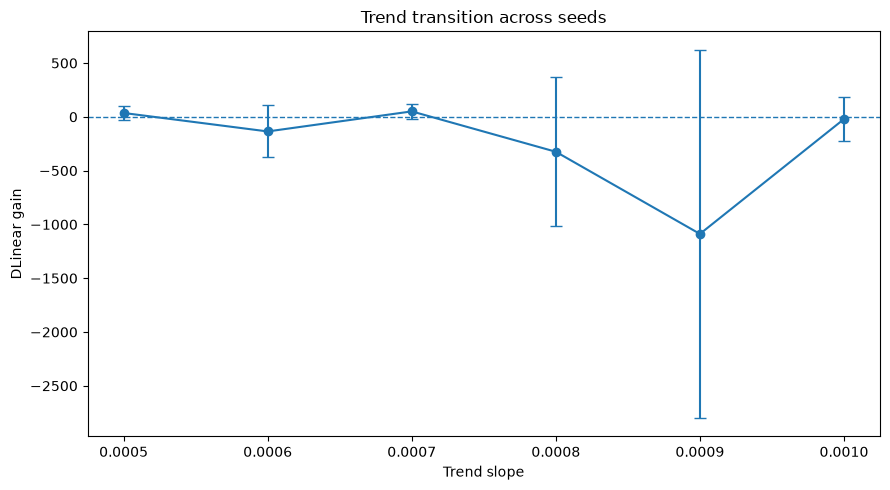

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))

x = transition_summary.index.to_numpy()
mean = transition_summary["mean"].to_numpy()
std = transition_summary["std"].to_numpy()

ax.errorbar(
    x,
    mean,
    yerr=std,
    marker="o",
    capsize=4
)

ax.axhline(0, linestyle="--", linewidth=1)

ax.set_xlabel("Trend slope")
ax.set_ylabel("DLinear gain")
ax.set_title("Trend transition across seeds")

plt.tight_layout()
plt.show()

In [6]:
# Transfer from synthetic - real data 

real = datasets["real"]

real_geometry = real.pivot_table(
    index=["L/P", "T/P"],
    columns="Model",
    values="MSE"
)

real_geometry["Gain_%"] = (
    (real_geometry["Linear"] - real_geometry["DLinear"])
    / real_geometry["Linear"]
) * 100

transfer = pd.concat(
    [
        geometry["Gain_%"].rename("Synthetic_Gain"),
        real_geometry["Gain_%"].rename("Real_Gain")
    ],
    axis=1,
    join="inner"
)

transfer["Same_Direction"] = (
    (transfer["Synthetic_Gain"] > 0)
    == (transfer["Real_Gain"] > 0)
)

transfer.round(3)

Synthetic_Gain  Real_Gain  Same_Direction
L/P T/P                                           
1.0 1.0          -6.679      1.371           False
    4.0          -4.336    -23.715            True
4.0 1.0        -792.133     -9.811            True
    4.0        -306.243     -4.450            True

**Nhận xét:**
- Dlinear không cho thấy lợi thế nhất định của mình trong thí nghiệm này. Tuy nhiên, lợi thế của nó lại được nhìn thấy khi cấu trúc trend thay đổi.